## this script calculates the content similarity across countries

In [24]:
import pandas as pd
import numpy as np
import itertools
import multiprocessing as mp
from tqdm import tqdm
from scipy.spatial import distance
import random
import math
import seaborn as sns
import matplotlib.pyplot as plt
from multiprocessing import Pool
import os
import time

In [2]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"

In [3]:
embedding_file = np.load(embedding_path)
embedding = embedding_file['emb']
uids = embedding_file['uids']

In [4]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

In [5]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [6]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

### create an dict which records uid and the index in uids array to retrieve the embedding from the embedding array

In [7]:
uid_index_dict={}
for index, uid in tqdm(enumerate(uids)):
    uid_index_dict[uid]=index

84162157it [01:39, 846750.34it/s]


In [8]:
pub_all.head()

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
0,29768068,40806321.0,CAN,F,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
1,29768068,41639269.0,CAN,M,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
2,29768068,53722752.0,CAN,L,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
3,29768070,65683243.0,JPN,F,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012
4,29768070,79129017.0,JPN,M,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012


### convert pub_all into a dict with country as the key, discipline and publications as the value

In [8]:
def convert_df_to_dict(df):
    cntry_dis_dict = {}
    
    for row in tqdm(df.values):
        uid = row[0]
        cntry = row[1]
        dis = row[2]
        
        # Check if the key_A already exists in the nested dictionary
        if cntry in cntry_dis_dict:
            # Check if the key_B already exists for the key_A
            if dis in cntry_dis_dict[cntry]:
                # Append the value_C to the existing list
                cntry_dis_dict[cntry][dis].append(uid)
            else:
                # Create a new key_B entry with a list containing value_C
                cntry_dis_dict[cntry][dis] = [uid]
        else:
            # Create a new key_A entry with a nested dictionary containing key_B and value_C
            cntry_dis_dict[cntry] = {dis: [uid]}
    
    return cntry_dis_dict

### choose national publications

In [9]:
pub_national = pub_all[pub_all.intl==0] #select national publications
pub_national = pub_national[['uid','cntry','dis']].drop_duplicates()

### replace the discipline code to higher level

In [10]:
path = "../../data/dropbox/LaborDivision/data/additionaldata/list_discipline.txt"
dis_df = pd.read_csv(path,sep="|", on_bad_lines='skip')
dis_map = dict(zip(dis_df['Code_Discipline'],dis_df['EDiscipline']))

In [11]:
pub_national = pub_national.replace(to_replace={'dis':dis_map})

In [12]:
pub_national_dict = convert_df_to_dict(pub_national)

100%|██████████████████████████| 13411314/13411314 [00:10<00:00, 1311478.68it/s]


In [13]:
def return_embeddings(uidlist, uid_index_dict, embedding):
    embedding_index = [uid_index_dict[uid] for uid in uidlist if uid in uid_index_dict]
    if embedding_index:
        embedding_vectors = embedding[embedding_index]
        return embedding_vectors
    return None

In [14]:
def precompute_embeddings(pub_dict, uid_index_dict, embedding):
    embeddings = {}
    for cntry, disciplines in pub_dict.items():
        embeddings[cntry] = {}
        for dis in disciplines.keys():
            emb = return_embeddings(disciplines[dis], uid_index_dict, embedding)
            if emb is not None:
                embeddings[cntry][dis] = emb
    return embeddings

In [91]:
disciplinelist = list(pub_national['dis'].unique())
cntrys = list(pub_national_dict.keys())
cntry_dis_embedding_raw = precompute_embeddings(pub_national_dict, uid_index_dict, embedding)
cntry_similarity_raw = cal_similarity(cntry_dis_embedding_raw, cntrys, disciplinelist)

In [67]:
def sample_embeddings(cntry_dis_emb_raw, minimum_size=20, sample_size=100):
    embeddings_sample = {}
    for cntry, dis_pubs in cntry_dis_emb_raw.items():
        embeddings_sample[cntry]={}
        for dis, pubs in dis_pubs.items():
            if pubs is not None and pubs.shape[0]> minimum_size:
                resampled_indices = np.random.choice(len(pubs), size=sample_size, replace=True)
                embeddings_sample[cntry][dis] = pubs[resampled_indices]
    return embeddings_sample

In [87]:
int_num=100
embeddings_sampled = []
for i in range(int_num):
    sampled = sample_embeddings(cntry_dis_embedding_raw)
    embeddings_sampled.append(sampled)

In [82]:
def calculate_similarity_for_embedding(args):
    cntry_dis_embedding, cntrylist, disciplinelist = args
    results = []
    
    for cntry1, cntry2 in itertools.combinations(cntrylist, 2):
        for dis in disciplinelist:
            emb_cntry1 = cntry_dis_embedding[cntry1].get(dis)
            emb_cntry2 = cntry_dis_embedding[cntry2].get(dis)
            
            if emb_cntry1 is not None and emb_cntry2 is not None:
                similarity = 1 - distance.cosine(np.mean(emb_cntry1, axis=0), np.mean(emb_cntry2, axis=0))
                results.append([cntry1, cntry2, dis, similarity])
                results.append([cntry2, cntry1, dis, similarity])
    
    return results

In [83]:
def parallel_calculation(cntry_dis_embeddings, cntrylist, disciplinelist, max_processes=60):
    total_embeddings = len(cntry_dis_embeddings)
    results = []
    
    # Process the embeddings in batches
    for i in range(0, total_embeddings, max_processes):
        batch_embeddings = cntry_dis_embeddings[i:i + max_processes]
        args = [(embedding, cntrylist, disciplinelist) for embedding in batch_embeddings]

        with Pool(processes=min(max_processes, len(batch_embeddings))) as pool:
            batch_results = list(tqdm(pool.imap(calculate_similarity_for_embedding, args), total=len(args)))
        
        # Collect the results
        results.extend(batch_results)
    
    # Flatten the results if needed
    flattened_results = [item for sublist in results for item in sublist]
    
    return flattened_results

In [ ]:
disciplinelist = list(pub_national['dis'].unique())
cntrys = list(pub_national_dict.keys())

In [ ]:
cntry_dis_embedding_raw = precompute_embeddings(pub_national_dict, uid_index_dict, embedding)

In [123]:
cntry_similarity_raw = parallel_calculation([cntry_dis_embedding_raw], cntrys, disciplinelist, max_processes=1)

100%|████████████████████████████████████████████| 1/1 [02:28<00:00, 148.73s/it]


In [90]:
results = parallel_calculation(embeddings_sampled, cntrys, disciplinelist, max_processes=60)

100%|███████████████████████████████████████████| 40/40 [00:25<00:00,  1.55it/s]


In [93]:
cntry_similarity_sampled = pd.DataFrame(results, columns=['cntry1','cntry2','dis','similarity'])

In [124]:
def convert_to_df(result):
    df = pd.DataFrame(result, columns=['cntry1','cntry2','dis','similarity'])
    df = df.groupby(['cntry1','cntry2','dis'])['similarity'].mean().reset_index()
    df = df.groupby(['cntry1','cntry2'])['similarity'].mean().reset_index()
    return df

In [125]:
cntry_similarity_sampled = convert_to_df(results)

In [126]:
cntry_similarity_raw = convert_to_df(cntry_similarity_raw)

In [110]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_dict = dict(zip(stgroup_df['Code'], stgroup_df['ST']))
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [112]:
cntry_similarity_sampled.head(2)

,cntry1,cntry2,dis,similarity
0,AFG,ALB,Clinical Medicine,0.955954
1,AFG,ARE,Clinical Medicine,0.919602


In [127]:
def merge_group(df, groupdict):
    df['group1'] = df['cntry1'].map(groupdict)
    df['group2'] = df['cntry2'].map(groupdict)
    return df

In [128]:
cntry_similarity_raw = merge_group(cntry_similarity_raw, stgroup_dict)
cntry_similarity_sampled = merge_group(cntry_similarity_sampled, stgroup_dict)

In [129]:
cntry_similarity_raw

,cntry1,cntry2,similarity,group1,group2
0,ABW,AFG,0.819457,Lagging,Lagging
1,ABW,AGO,0.949847,Lagging,Lagging
2,ABW,ALB,0.859298,Lagging,Lagging
3,ABW,ARE,0.878409,Lagging,Lagging
4,ABW,ARG,0.853883,Lagging,Developing
...,...,...,...,...,...
38303,ZWE,WSM,0.594885,Lagging,Lagging
38304,ZWE,XKX,0.711484,Lagging,Lagging
38305,ZWE,YEM,0.789533,Lagging,Lagging
38306,ZWE,ZAF,0.850185,Lagging,Proficient


In [130]:
def group_by_group(df):
    df = df.groupby(['group1','group2'])['similarity'].mean().reset_index()
    df = df.pivot(index='group1', columns='group2', values='similarity')
    return df

In [131]:
group_raw = group_by_group(cntry_similarity_raw)
group_sampled = group_by_group(cntry_similarity_sampled)

In [132]:
group_raw

group2,Advanced,Developing,Lagging,Proficient
group1,,,,
Advanced,0.973001,0.883537,0.790703,0.950043
Developing,0.883537,0.862148,0.780832,0.887257
Lagging,0.790703,0.780832,0.740984,0.790315
Proficient,0.950043,0.887257,0.790315,0.937695


### plot

In [135]:
def plot(df):
    order = ['Advanced','Proficient','Developing','Lagging']
    df = df[order]
    df = df.reindex(order)
    
    fig, ax = plt.subplots()
    mask = np.tril(np.ones_like(df, dtype=bool),k=-1)
    sns.heatmap(df, cmap='viridis', annot=True, fmt=".2f", mask=mask, ax=ax)
    ax.xaxis.set_ticks_position('top')  # Move ticks to the top
    ax.xaxis.set_label_position('top')  # Move label to the top

    # Remove minor ticks
    ax.tick_params(axis='x', which='both', bottom=False, top=False)

    # If you want to remove minor ticks for y-axis as well
    ax.tick_params(axis='y', which='both', left=False, right=False)
    ax.set_xlabel("")
    ax.set_ylabel("")
    return fig, ax

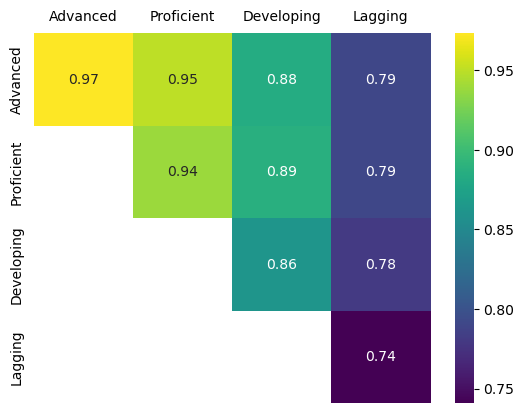

In [138]:
fig, ax = plot(group_raw)
plt.savefig('../../data/dropbox/LaborDivision/figs/similarity_across_cntrys.pdf',bbox_inches='tight')

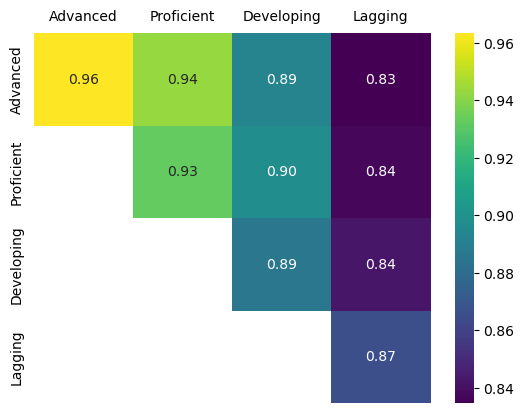

In [139]:
plot(group_sampled)
plt.savefig('../../data/dropbox/LaborDivision/figs/similarity_across_cntrys_sampled.pdf',bbox_inches='tight')